# Blocks and diagrams

The core of sigline in one pass: a signal chain from library blocks, a
block of your own, feedback, sweeps, sample rates, functions as blocks,
subsystems and drawings. Each result is checked against a closed form or
a SciPy one-shot reference.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal as sig

import sigline as sl

fs = 48_000.0

## 1. A signal chain

Two tones and noise, low-passed, mixed up by 5 kHz. Arithmetic on signals
adds the blocks (`+` a `Sum`, a number times a signal a `Gain`); `>>` draws
a line. `d.probe` records the filter input without a line to a `Scope`. In
Jupyter a diagram shows itself as its drawing.

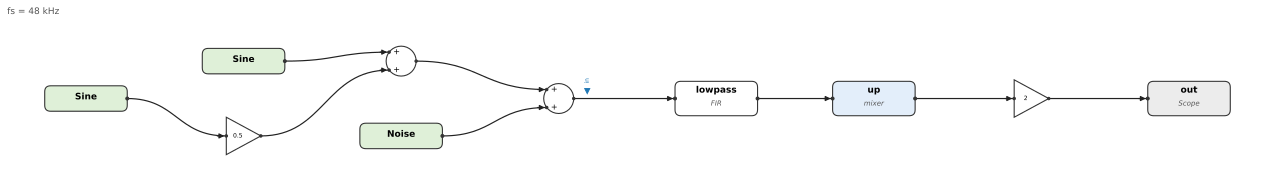

In [2]:
taps = sig.firwin(101, 3e3, fs=fs)
x = sl.Sine(1e3) + 0.5 * sl.Sine(9e3) + sl.Noise(0.05, seed=2)
lp, out = sl.FIR(taps, name="lowpass"), sl.Scope("out")
x >> lp >> sl.mixer(5e3, name="up") >> sl.Gain(2.0) >> out
d = sl.Diagram(out, fs=fs)
inp = d.probe(x, name="in")
d

max |error| vs one-shot: 1.2e-11


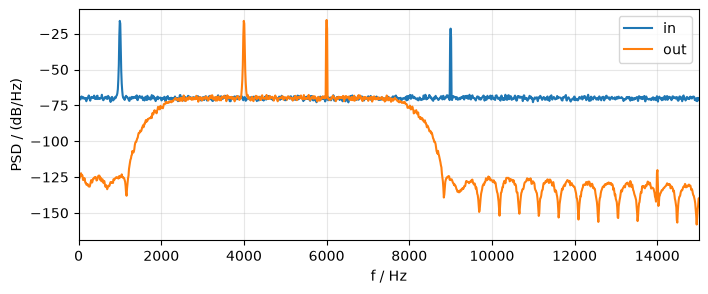

In [3]:
d.run(1.0, chunk=1024)

# reference: the whole recording through scipy in one call
n = np.arange(d.n)
ref = 2 * sig.lfilter(taps, 1, inp.data) * np.cos(2 * np.pi * 5e3 * n / fs)
print(f"max |error| vs one-shot: {np.max(np.abs(out.data - ref)):.1e}")

fig, ax = plt.subplots(figsize=(8, 3))
inp.plot_psd(ax=ax)
out.plot_psd(ax=ax)
ax.set_xlim(0, 15e3)
plt.show()

## 2. A block of your own

A block stores its parameters, creates its state in `reset()` and processes
one chunk in `step`; it carries the state to the next chunk. Here a leaky
integrator, $y[n] = a\,y[n-1] + (1-a)\,x[n]$. A block is also a function:
calling it processes one chunk. `assert_chunk_invariant` runs it in many
chunkings and compares; a block that forgets its state fails.

In [4]:
from sigline.testing import assert_chunk_invariant


class Leaky(sl.Block):
    def __init__(self, a, **kw):
        self.a = a  # parameters first: super().__init__ calls reset()
        super().__init__(**kw)

    def reset(self):
        self.zi = np.zeros(1)

    def step(self, x):
        y, self.zi = sig.lfilter([1 - self.a], [1, -self.a], x, zi=self.zi)
        return y


x = np.random.default_rng(0).standard_normal(500)
leaky = Leaky(0.9)
y = np.r_[leaky(x[:200]), leaky(x[200:])]  # two calls, one signal
err = np.max(np.abs(y - sig.lfilter([0.1], [1, -0.9], x)))
print(f"max |error| vs lfilter: {err:.1e}")
assert_chunk_invariant(lambda: Leaky(0.9), x)
print("Leaky: chunk invariant")


class Forgetful(sl.Block):
    def step(self, x):
        return sig.lfilter([0.1], [1, -0.9], x)  # no state kept


try:
    assert_chunk_invariant(Forgetful, x)
except AssertionError as err:
    print(str(err).splitlines()[0])

max |error| vs lfilter: 4.4e-16
Leaky: chunk invariant
after reset(): output 'y' differs from the one-chunk run first at sample 166: 0.008661926298854213 != -0.13205054865525678 (max error 0.157)


## 3. Feedback: an echo

$y[n] = x[n] + g\,y[n-D]$: the sum drives a `Delay` whose output returns
through a gain. A delay by $D$ breaks the loop for chunks up to $D$, so the
loop runs vectorised. Longer chunks need the loop's output within the chunk:
the diagram runs it sample by sample, compiled with numba (a loop cluster).
Both give the impulse response $g^k$ at $n = kD$.

chunk  400: max |error| vs closed form 2.8e-17


chunk 1024: max |error| vs closed form 2.8e-17
[<LoopCluster loop[add, echo, g] numba>]


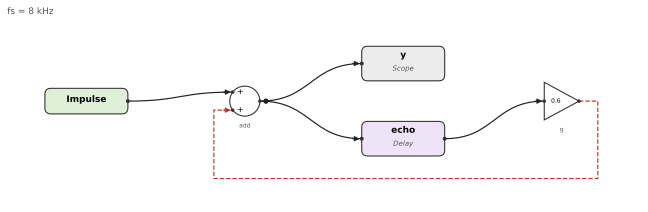

In [5]:
g, D = 0.6, 400  # a 50 ms echo at 8 kHz


def echo(source, g, D):
    add, rec = sl.Sum(name="add"), sl.Scope("y")
    source >> add["x0"]
    add >> sl.Delay(D, name="echo") >> sl.Gain(g, name="g") >> add["x1"]
    add >> rec
    return sl.Diagram(rec, fs=8000.0), rec


d, rec = echo(sl.Impulse(), g, D)
n = np.arange(3200)
h = np.where(n % D == 0, g ** (n // D), 0.0)
for chunk in (D, 1024):
    d.reset().run(n=3200, chunk=chunk)
    err = np.max(np.abs(rec.data - h))
    print(f"chunk {chunk:4d}: max |error| vs closed form {err:.1e}")
print(d.loops())
d

## 4. A sweep is a `for` loop

Change an attribute, reset, run. White noise through the echo, gain swept:
the output variance is $\sigma^2 / (1 - g^2)$.

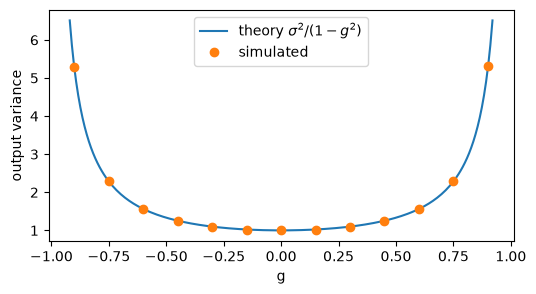

In [6]:
d, rec = echo(sl.Noise(1.0, seed=3), 0.0, 64)
gains = np.linspace(-0.9, 0.9, 13)
measured = []
for k in gains:
    d["g"].g = k
    d.reset().run(n=200_000, chunk=64)
    measured.append(np.var(rec.data[1000:]))

fine = np.linspace(-0.92, 0.92, 200)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(fine, 1 / (1 - fine**2), label=r"theory $\sigma^2/(1-g^2)$")
ax.plot(gains, measured, "o", label="simulated")
ax.set(xlabel="g", ylabel="output variance")
ax.legend()
plt.show()

## 5. Sample rates

Rates propagate along the lines: `Decimate(4)` low-passes and keeps every
fourth sample, so everything after it runs at a quarter of the rate. Chunks
and run lengths are multiples of `d.granularity`.

Sine4          8000 Hz ->   8000 Hz
Noise3         8000 Hz ->   8000 Hz
Sum5           8000 Hz ->   8000 Hz
Decimate1      8000 Hz ->   2000 Hz
low            2000 Hz ->   2000 Hz
max |error| vs filter and slice: 8.9e-16


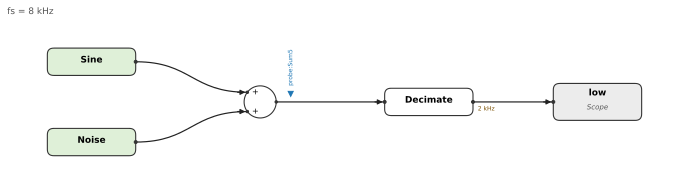

In [7]:
src, dec, low = sl.Sine(200.0) + sl.Noise(0.3, seed=2), sl.Decimate(4), sl.Scope("low")
src >> dec >> low
d = sl.Diagram(low, fs=8000.0)
raw = d.probe(src)
d.run(0.05, chunk=1000)
for name, (f_in, f_out) in d.rates().items():
    print(f"{name:12s} {f_in:6.0f} Hz -> {f_out:6.0f} Hz")
ref = sig.lfilter(dec.taps, 1, raw.data)[::4]
print(f"max |error| vs filter and slice: {np.max(np.abs(low.data - ref)):.1e}")
d

## 6. Functions as blocks

`FuncChunk(fn)` calls `fn` on whole chunks: for what NumPy vectorises.
`FuncSingle(f)` calls `f` once per sample, in scalar Python with `if` and
state, compiled with numba. A Schmitt trigger needs both: a comparator flips
on every noise crossing; with hysteresis the output switches once per
crossing of the threshold band.

output changes in 1.5 periods: {'comparator': 11, 'trigger': 3}


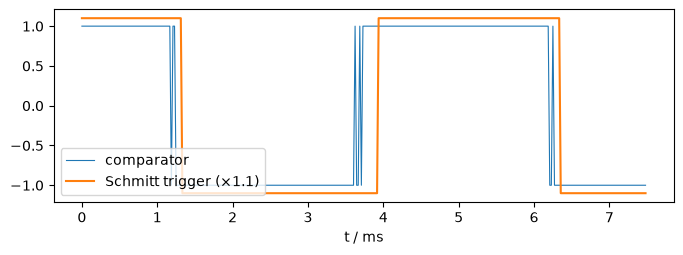

In [8]:
def schmitt(x, s, hi=0.3, lo=-0.3):
    # s: the last output, kept between samples
    if x > hi:
        s = 1.0
    elif x < lo:
        s = -1.0
    return s, s


noisy = sl.Sine(200.0) + sl.Noise(0.1, seed=3)
comparator, trigger = sl.Scope("comparator"), sl.Scope("trigger")
noisy >> sl.FuncChunk(np.sign, name="sign") >> comparator
noisy >> sl.FuncSingle(schmitt, state=-1.0, name="schmitt") >> trigger
d = sl.Diagram(comparator, trigger, fs=fs)
d.run(0.0075)

flips = {sc.name: int(np.sum(np.diff(sc.data) != 0)) for sc in (comparator, trigger)}
print("output changes in 1.5 periods:", flips)
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.plot(1e3 * d.t, comparator.data, lw=0.8, label="comparator")
ax.plot(1e3 * d.t, 1.1 * trigger.data, lw=1.5, label="Schmitt trigger (×1.1)")
ax.set(xlabel="t / ms")
ax.legend(loc="lower left")
plt.show()

## 7. Subsystems and drawings

A function that wires blocks and returns a `Subsystem` is a reusable part;
from outside it is one block, inside every block stays reachable by name
and replaceable. Library parts like `mixer` are made this way.

FIR: 13 kHz -25 dB, image at 7 kHz -87 dB
IIR: 13 kHz -25 dB, image at 7 kHz -48 dB


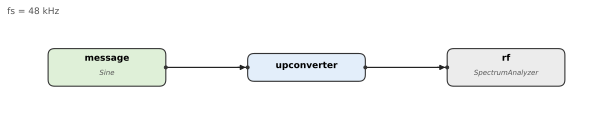

In [9]:
def upconverter(fc, cutoff):
    mix = sl.Product(name="mix")
    sl.Sine(fc, name="lo") >> mix["x1"]
    hpf = mix >> sl.FIR(sig.firwin(101, cutoff, pass_zero=False, fs=fs), name="hpf")
    return sl.Subsystem(inputs={"x": mix["x0"]}, outputs={"y": hpf})


up = upconverter(10e3, 10e3)
spec = sl.SpectrumAnalyzer(nfft=2048, skip=200, name="rf")
sl.Sine(3e3, name="message") >> up >> spec
d = sl.Diagram(spec, fs=fs)
d.run(0.5)
level = lambda f: 10 * np.log10(spec.psd[np.argmin(np.abs(spec.f - f))])  # noqa: E731
print(f"FIR: 13 kHz {level(13e3):.0f} dB, image at 7 kHz {level(7e3):.0f} dB")

up.replace(
    up.hpf, sl.IIR(sos=sig.butter(6, 10e3, "highpass", fs=fs, output="sos"), name="hpf")
)
d.reset().run(0.5)
print(f"IIR: 13 kHz {level(13e3):.0f} dB, image at 7 kHz {level(7e3):.0f} dB")
d

`draw(expand=True)` opens subsystems; `print(d)` gives the signal flow as
text; `to_dot()` and `to_mermaid()` give Graphviz and Mermaid sources (for
Typst's `diagraph` or Markdown on GitHub).

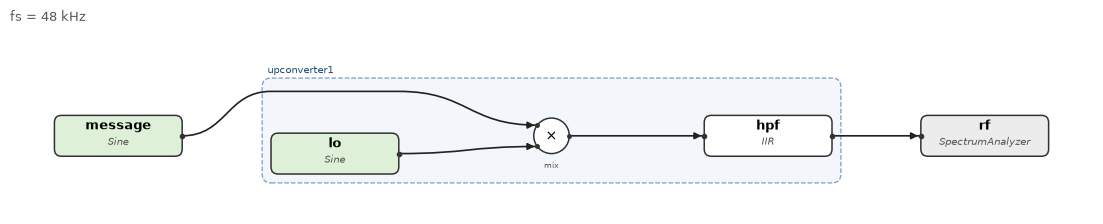

Diagram  fs = 48 kHz  |  3 blocks, 2 lines, 0 feedback

signal flow:
  message ──▶ upconverter1 ──▶ rf

blocks:
  [0] message       Sine              3 kHz
  [1] upconverter1  upconverter       3 blocks
  [2] rf            SpectrumAnalyzer  2048-pt, mean
flowchart LR
  upconverter1["upconverter"]
  rf["rf<br/><small>SpectrumAnalyzer</small>"]
  message["message<br/><small>Sine</small>"]
  upconverter1 --> rf
  message --> upconverter1


In [10]:
d.draw(expand=True)
plt.show()
print(d)
print(d.to_mermaid())

## 8. Checks

The first chunk after a build or `reset()` is checked: NaN or Inf names the
first block that produced it.

In [11]:
d["message"].amp = float("inf")
try:
    d.reset().run(0.01)
except FloatingPointError as err:
    print(err)

message['y'] (Sine) produced NaN/Inf at sample 0 of this chunk; its inputs were finite, so this block is the first one to fail


## Summary

- Blocks wired with `>>` and operators; `Diagram` runs them in chunks, and
  chunking never changes results.
- Own blocks: parameters as attributes, state from `reset()`, one chunk per
  `step`; `assert_chunk_invariant` tests them.
- Feedback through delays runs vectorised, other loops sample by sample.
- Sweeps are `for` loops; rates propagate; `FuncChunk` and `FuncSingle`
  turn functions into blocks; subsystems are functions returning blocks.